# Data exploration: how well do the references track the targets?

Measured on the training period, before fitting any model.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from get_dataset import get_data, target_turbines, reference_turbines

In [2]:
# same split as pipeline.ipynb: train = complete rows outside the test period and the outage
ds_train, ds_test, ds_result = get_data(data_dir="data", test_start="2026-09-04", use_non_complete=False)
print(f"train {ds_train.index[0]} -> {ds_train.index[-1]}  {len(ds_train)} rows")

train 2026-07-01 00:00:00 -> 2026-08-31 23:40:00  7622 rows


## Which reference tracks each target best?

Before fitting anything: Pearson r of every reference (H1-H5, O1, O2) against every target (T1-T3) over the
training period, on the 10-minute data. Rule of thumb from the paper: **r > 0.65** for 10-minute data.
The last row is the average of all references, the input of the `neighbour_mean` model.

In [3]:
R_THRESHOLD = 0.65   # rule of thumb for 10-minute data

wind_train = ds_train.xs("wind_speed", axis=1, level=1)
refs, targets = reference_turbines(ds_train), target_turbines(ds_train)

corr = pd.DataFrame({t: {ref: wind_train[ref].corr(wind_train[t]) for ref in refs} for t in targets})
corr.loc["mean(all refs)"] = [wind_train[refs].mean(axis=1).corr(wind_train[t]) for t in targets]
corr.index.name, corr.columns.name = "reference", "target"

best_single = corr.loc[refs].idxmax()
pd.DataFrame({
    "best single reference": best_single,
    "r": [corr.loc[ref, t] for t, ref in best_single.items()],
    "r of mean(all refs)": corr.loc["mean(all refs)"],
    f"references with r > {R_THRESHOLD}": [", ".join(r for r in refs if corr.loc[r, t] > R_THRESHOLD) for t in targets],
}).round(3)

,best single reference,r,r of mean(all refs),references with r > 0.65
target,,,,
T1,O1,0.711,0.735,"H1, O1, O2"
T2,O2,0.776,0.808,"H1, H2, H3, H4, H5, O1, O2"
T3,O1,0.748,0.784,"H1, H2, H3, H4, H5, O1, O2"


In [4]:
# chart style: light surface, recessive grid; T1-T3 always blue, orange, aqua (+ own marker shape)
SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
TARGET_COLOR = dict(zip(targets, ["#2a78d6", "#eb6834", "#1baf7a"]))
TARGET_MARKER = dict(zip(targets, ["o", "s", "D"]))
BLUES = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})


def shade(v):
    """Below the rule of thumb: grey. Above: light to dark blue with r."""
    if v <= R_THRESHOLD:
        return f"background-color: #f0efec; color: {MUTED}"
    frac = min((v - R_THRESHOLD) / (0.85 - R_THRESHOLD), 1.0)
    text = "#ffffff" if frac > 0.6 else INK
    return f"background-color: {plt.matplotlib.colors.to_hex(BLUES(frac))}; color: {text}"


# the table: grey = r <= 0.65, darker blue = tracks the target better, bold = best single reference
(corr.style
    .format("{:.3f}")
    .map(shade)
    .apply(lambda col: ["font-weight: bold" if ref == best_single[col.name] else "" for ref in col.index])
    .set_caption(f"Pearson r with each target, 10-minute training data ({len(wind_train)} rows)"))

target,T1,T2,T3
reference,,,
H1,0.664,0.676,0.666
H2,0.623,0.678,0.675
H3,0.643,0.731,0.692
H4,0.627,0.698,0.685
H5,0.645,0.721,0.698
O1,0.711,0.772,0.748
O2,0.692,0.776,0.743
mean(all refs),0.735,0.808,0.784


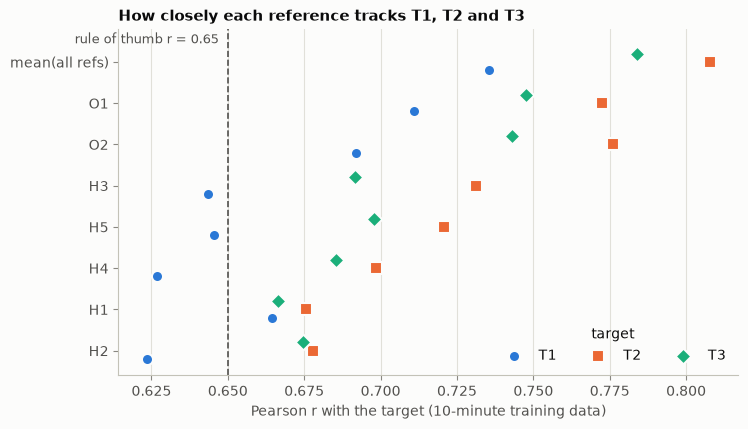

In [5]:
# r per reference and target, weakest reference at the bottom; dashed line = rule of thumb
order = corr.mean(axis=1).sort_values().index
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, t in enumerate(targets):
    ax.scatter(corr.loc[order, t], y + (i - 1) * 0.2, s=64, color=TARGET_COLOR[t], marker=TARGET_MARKER[t],
               edgecolor=SURFACE, linewidth=1.5, label=t, zorder=3)
ax.axvline(R_THRESHOLD, color=INK_2, linestyle="--", linewidth=1.2, zorder=2)
ax.text(R_THRESHOLD - 0.003, len(order) - 0.45, f"rule of thumb r = {R_THRESHOLD}", ha="right", va="center",
        color=INK_2, fontsize=9)
ax.set_yticks(y, order)
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.6, len(order) - 0.2)
ax.set_xlabel("Pearson r with the target (10-minute training data)")
ax.set_title("How closely each reference tracks T1, T2 and T3")
ax.legend(title="target", loc="lower right", ncols=3)
plt.show()

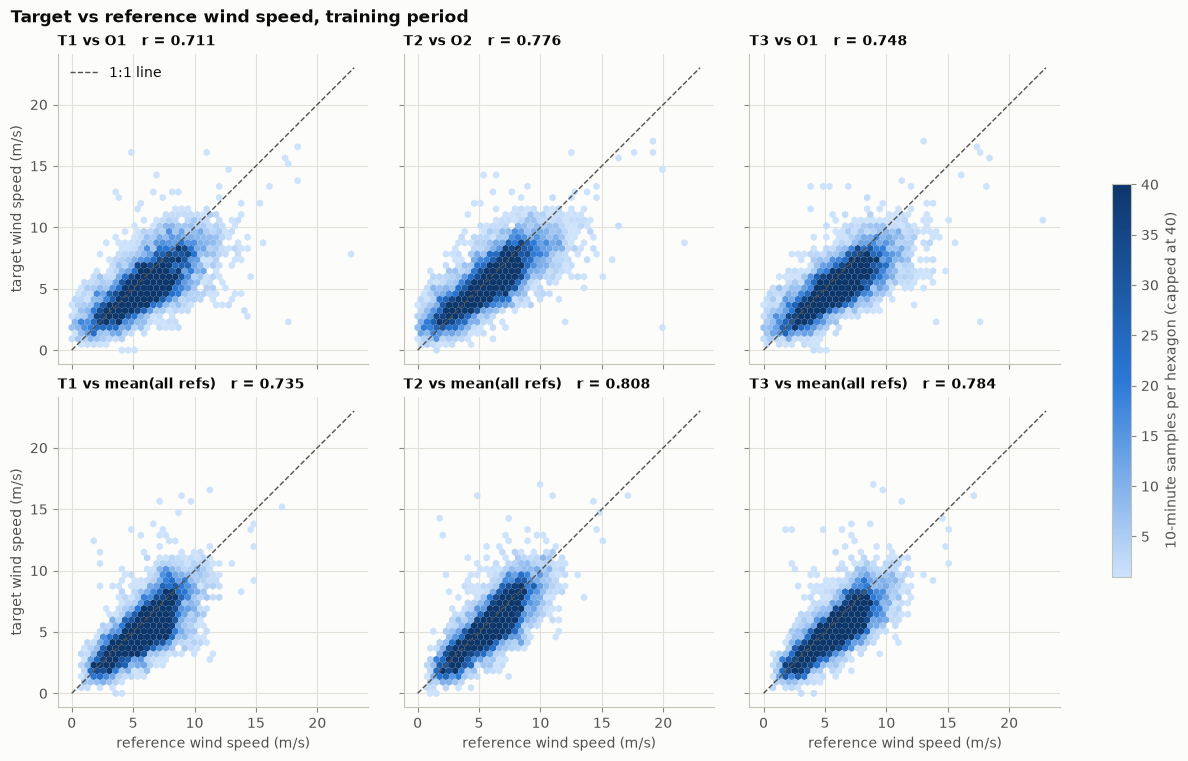

In [6]:
# what the r values look like: target vs its best single reference (top) and vs mean(all refs) (bottom)
fig, axes = plt.subplots(2, len(targets), figsize=(12, 7.5), sharex=True, sharey=True, layout="constrained")
lim = [0, np.ceil(wind_train.max().max())]
for col, t in enumerate(targets):
    for row, (label, x) in enumerate([(best_single[t], wind_train[best_single[t]]),
                                      ("mean(all refs)", wind_train[refs].mean(axis=1))]):
        ax = axes[row, col]
        hb = ax.hexbin(x, wind_train[t], gridsize=45, extent=lim + lim, cmap=BLUES, mincnt=1,
                       vmax=40, linewidths=0)
        ax.plot(lim, lim, color=INK_2, linestyle="--", linewidth=1, label="1:1 line")
        ax.set_title(f"{t} vs {label}   r = {corr.loc[label, t]:.3f}", fontsize=10)
        ax.set_aspect("equal")
        if row == 1:
            ax.set_xlabel("reference wind speed (m/s)")
        if col == 0:
            ax.set_ylabel(f"target wind speed (m/s)")
axes[0, 0].legend(loc="upper left")
fig.colorbar(hb, ax=axes, shrink=0.6, label="10-minute samples per hexagon (capped at 40)")
fig.suptitle("Target vs reference wind speed, training period", x=0.02, ha="left", fontweight="bold")
plt.show()

## Wind direction of all turbines

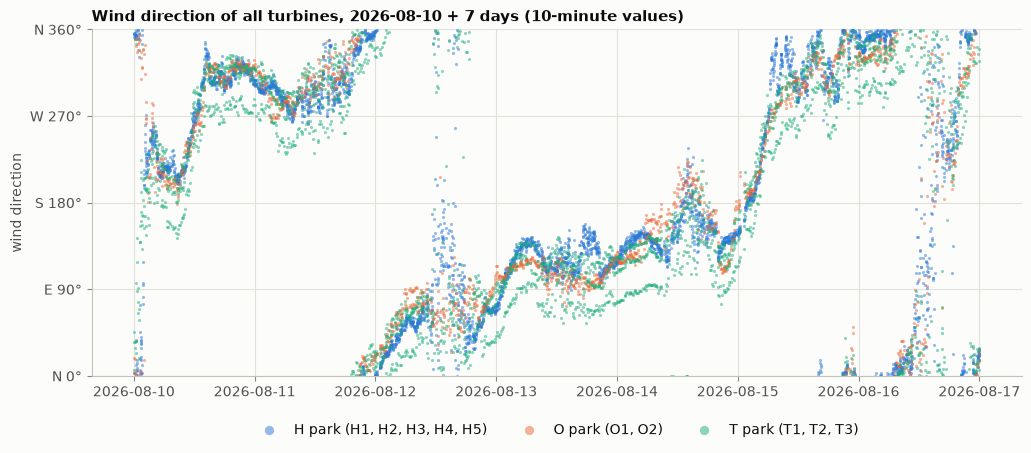

In [7]:
# wind direction of all turbines in one graph, one colour per group, over one week of the training period
START, DAYS = "2026-08-10", 7
GROUP_COLOR = {"H": "#2a78d6", "O": "#eb6834", "T": "#1baf7a"}

dir_train = ds_train.xs("wind_direction", axis=1, level=1)
week = dir_train.loc[START:pd.Timestamp(START) + pd.Timedelta(days=DAYS)]

fig, ax = plt.subplots(figsize=(12, 4.5))
for group, color in GROUP_COLOR.items():   # targets drawn last, on top
    members = [t for t in week.columns if t.startswith(group)]
    for i, t in enumerate(members):
        ax.scatter(week.index, week[t], s=5, color=color, alpha=0.5, linewidths=0,
                   label=f"{group} park ({', '.join(members)})" if i == 0 else None)
ax.set_ylim(0, 360)
ax.set_yticks(range(0, 361, 90), ["N 0°", "E 90°", "S 180°", "W 270°", "N 360°"])
ax.set_ylabel("wind direction")
ax.set_title(f"Wind direction of all turbines, {START} + {DAYS} days (10-minute values)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=3, markerscale=3)
plt.show()

### Wind direction correlation: references vs targets

Direction is circular (359° and 1° are 2° apart), so plain Pearson r on degrees would be wrong.
`circular r` is the circular correlation of Jammalamadaka & SenGupta: like Pearson r (-1..1), but computed on
the angles around their circular means. It ignores a constant offset between two turbines, so the
`mean offset` (target minus reference, in degrees) is shown next to it.

In [8]:
def circular_mean(rad):
    """Mean direction of angles in radians (via the mean unit vector)."""
    return np.angle(np.exp(1j * rad).mean())


def circular_corr(a, b):
    """Circular correlation of two direction series in degrees (Jammalamadaka & SenGupta), -1..1."""
    ok = a.notna() & b.notna()
    a, b = np.radians(a[ok].to_numpy()), np.radians(b[ok].to_numpy())
    sa, sb = np.sin(a - circular_mean(a)), np.sin(b - circular_mean(b))
    return (sa * sb).sum() / np.sqrt((sa**2).sum() * (sb**2).sum())


def mean_offset(ref, target):
    """Mean direction difference target - reference in degrees, -180..180."""
    ok = ref.notna() & target.notna()
    return np.degrees(circular_mean(np.radians(target[ok].to_numpy() - ref[ok].to_numpy())))


dir_corr = pd.DataFrame({t: {ref: circular_corr(dir_train[ref], dir_train[t]) for ref in refs} for t in targets})
dir_offset = pd.DataFrame({t: {ref: mean_offset(dir_train[ref], dir_train[t]) for ref in refs} for t in targets})
dir_corr.index.name = dir_offset.index.name = "reference"

r_lo, r_hi = dir_corr.min().min(), dir_corr.max().max()


def shade_r(v):
    """Light to dark blue with circular r (relative to the range in this table)."""
    frac = (v - r_lo) / (r_hi - r_lo)
    text = "#ffffff" if frac > 0.5 else INK
    return f"background-color: {plt.matplotlib.colors.to_hex(BLUES(frac))}; color: {text}"


table = pd.concat({"circular r": dir_corr, "mean offset (°)": dir_offset}, axis=1)
(table.style
    .format("{:.3f}", subset=["circular r"])
    .format("{:+.1f}", subset=["mean offset (°)"])
    .map(shade_r, subset=["circular r"])
    .set_caption(f"Wind direction, reference vs target, 10-minute training data ({len(dir_train)} rows); "
                 f"colour spans this table's r range {r_lo:.3f}-{r_hi:.3f}"))

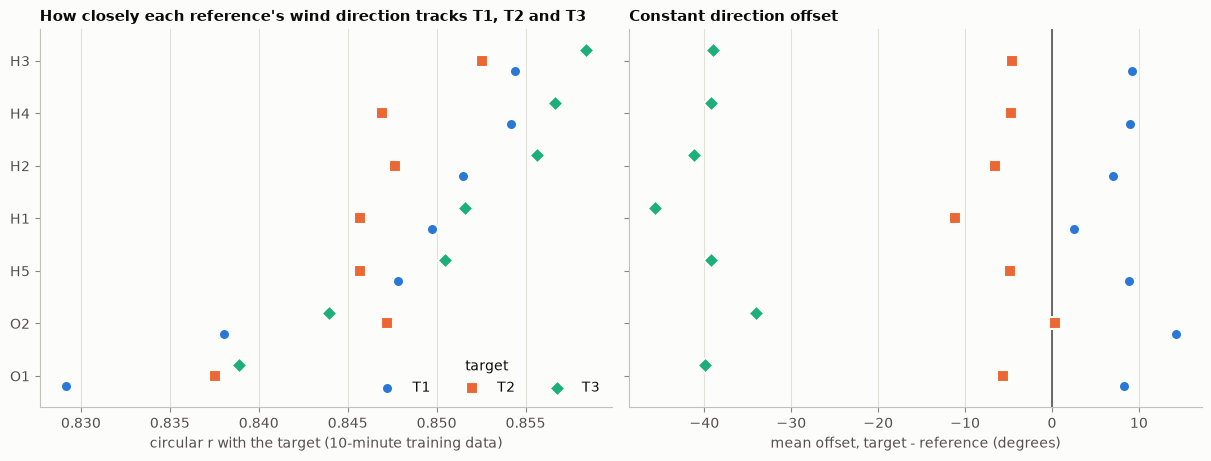

In [9]:
# left: circular r per reference and target; right: mean offset target - reference (0 = same direction)
order = dir_corr.mean(axis=1).sort_values().index
y = np.arange(len(order))

fig, (ax_r, ax_off) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout="constrained")
for i, t in enumerate(targets):
    style = dict(s=64, color=TARGET_COLOR[t], marker=TARGET_MARKER[t], edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax_r.scatter(dir_corr.loc[order, t], y + (i - 1) * 0.2, label=t, **style)
    ax_off.scatter(dir_offset.loc[order, t], y + (i - 1) * 0.2, **style)
ax_r.set_yticks(y, order)
ax_r.set_xlabel("circular r with the target (10-minute training data)")
ax_r.set_title("How closely each reference's wind direction tracks T1, T2 and T3")
ax_r.legend(title="target", loc="lower right", ncols=3)
ax_off.axvline(0, color=INK_2, linewidth=1.2, zorder=2)
ax_off.set_xlabel("mean offset, target - reference (degrees)")
ax_off.set_title("Constant direction offset")
for ax in (ax_r, ax_off):
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-0.6, len(order) - 0.4)
plt.show()

## Wind rose T1

Bar length = share of time the wind comes **from** that direction, colour = wind speed.
Speed bands follow the power curve: below 3 m/s no power, around 11.5 m/s rated power.

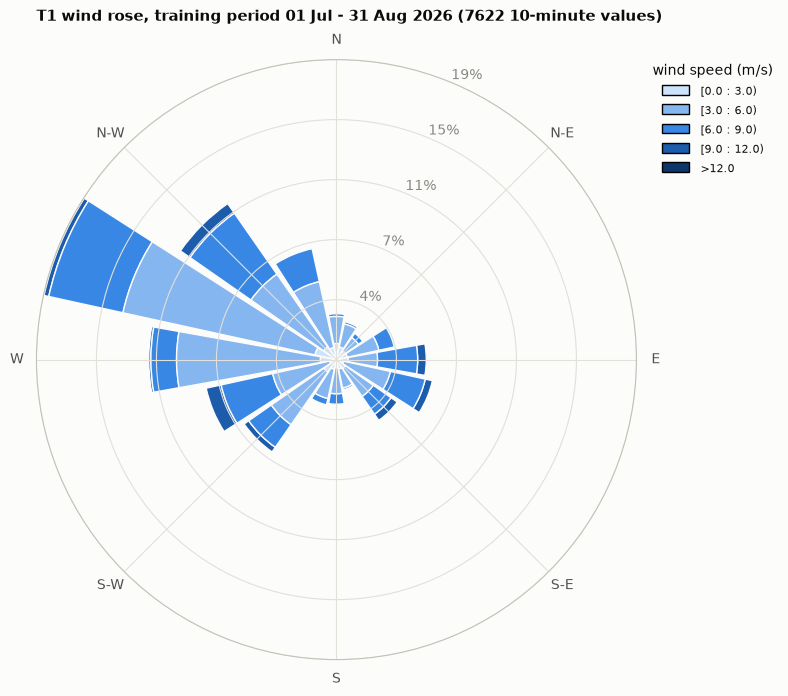

from,N,NNE,NE,ENE,E,ESE,SE,SSE,S,SSW,SW,WSW,W,WNW,NW,NNW
share_%,2.9,2.4,2.0,3.8,5.6,6.1,4.6,1.9,2.8,2.9,7.0,8.4,11.7,18.7,11.9,7.2
mean_speed_ms,3.8,3.8,4.1,4.9,6.0,5.8,5.5,3.6,4.6,4.3,5.1,6.2,4.8,5.3,5.9,5.2


In [10]:
from windrose import WindroseAxes

t1 = ds_train["T1"][["wind_direction", "wind_speed"]].dropna()
SPEED_BINS = [0, 3, 6, 9, 12]   # m/s, lower edges; the last band is 12 m/s and above
SPEED_COLORS = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # light = calm, dark = strong

fig = plt.figure(figsize=(7.5, 7.5))
ax = WindroseAxes.from_ax(fig=fig)
ax.bar(t1["wind_direction"], t1["wind_speed"], normed=True, nsector=16, bins=SPEED_BINS, colors=SPEED_COLORS,
       opening=0.9, edgecolor=SURFACE, linewidth=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="y", labelcolor=MUTED)
ax.set_legend(title="wind speed (m/s)", loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
ax.set_title(f"T1 wind rose, training period {t1.index[0]:%d %b} - {t1.index[-1]:%d %b %Y} ({len(t1)} 10-minute values)",
             pad=28)
plt.show()

# share of time per direction (16 sectors) and mean wind speed there
sector = ((t1["wind_direction"] + 11.25) % 360 // 22.5).astype(int)
names = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
pd.DataFrame({
    "share_%": (100 * sector.value_counts(normalize=True)).reindex(range(16), fill_value=0).to_numpy(),
    "mean_speed_ms": t1["wind_speed"].groupby(sector).mean().reindex(range(16)).to_numpy(),
}, index=pd.Index(names, name="from")).round(1).T